# LSB Matching Revisited
Jarno Mielikainen, IEEE SIGNAL PROCESSING LETTERS, VOL. 13, NO. 5, MAY 2006


## Wprowadzenie 

W klasycznej metodzie steganograficznej **LSB matching** ukrywanie danych polega na modyfikacji najmłodszego bitu piksela. Jeśli bit wiadomości nie zgadza się z bitem piksela, algorytm losowo dodaje lub odejmuje wartość 1. Ten wybór (dodawanie/odejmowanie) nie niesie ze sobą żadnej informacji. **Metoda LSBMR sprytnie wykorzystuje ten wybór do zakodowania dodatkowego, drugiego bitu wiadomości**.

Algorytm przetwarza piksele obrazu w parach $(x_i, x_{i+1})$, przekształcając je w parę stego-pikseli $(y_i, y_{i+1})$. Jedna para pikseli przechowuje dokładnie dwa bity tajnej wiadomości ($m_i, m_{i+1}$):
* **Pierwszy bit wiadomości ($m_i$)** jest wprost wpisany w najmłodszy bit pierwszego piksela: $m_i = \mathrm{LSB}(y_i)$.
* **Drugi bit wiadomości ($m_{i+1}$)** jest wynikiem specjalnej funkcji matematycznej zależnej od obu pikseli: $m_{i+1} = f(y_i, y_{i+1}) = \mathrm{LSB}\left(\lfloor y_i / 2 \rfloor + y_{i+1}\right)$.

Poniższa tabela przedstawia reguły modyfikacji pikseli podczas ukrywania danych:

| Zgodność $m_i$ z $\mathrm{LSB}(x_i)$ | Zgodność $m_{i+1}$ z $f(x_i, x_{i+1})$ | Wymagane działanie |
| :--- | :--- | :--- |
| **Zgodne** | **Zgodne** | **Brak zmian:** Oba piksele pozostają nienaruszone ($y_i = x_i$, $y_{i+1} = x_{i+1}$). |
| **Zgodne** | **Niezgodne** | **Modyfikacja drugiego piksela:** $y_i = x_i$, natomiast $y_{i+1} = x_{i+1} \pm 1$. (Każda zmiana drugiego piksela o 1 odwraca wynik funkcji $f$). |
| **Niezgodne** | *(obojętne)* | **Modyfikacja pierwszego piksela:** $y_{i+1} = x_{i+1}$, natomiast $y_i = x_i \pm 1$. Wybieramy wariant dodawania lub odejmowania tak, aby nowa wartość $f(y_i, y_{i+1})$ zgadzała się z poszukiwanym bitem $m_{i+1}$. |

#### Zalety i przypadki brzegowe

* **Mniej zniekształceń:** Pojemność informacyjna pozostaje taka sama jak w klasycznym LSB matching (1 bit ukryty w 1 pikselu). Jednak dzięki kodowaniu parami, średnia liczba modyfikowanych pikseli spada z 50% do **37,5%** (oczekiwana liczba zmian to $0{,}375$ na piksel).
* **Brak asymetrii (odporność na steganalizę):** Wybór kierunku modyfikacji ($\pm 1$) jest optymalizowany osobno dla obszarów o parzystych i nieparzystych wartościach pikseli, aby sumaryczna liczba dodawań i odejmowań znosiła się do zera. Zapobiega to asymetrii histogramu i utrudnia wykrycie ukrytych danych przez metody steganalizy.
* **Skrajne wartości (0 i 255):** Piksele o wartościach skrajnych są obsługiwane jawnie. Jeśli standardowa reguła wymagałaby wyjścia poza zakres (np. odjęcia 1 od wartości 0), algorytm stosuje poprawkę na drugim pikselu z pary, aby zachować poprawne wartości funkcji $f$ bez przekraczania dopuszczalnego zakresu piksela. Do odczytu wiadomości wystarczy ponownie obliczyć wartości $\mathrm{LSB}(y_i)$ oraz $f(y_i, y_{i+1})$ używając klucza pseudolosowego określającego kolejność par.

## Przygotowanie danych

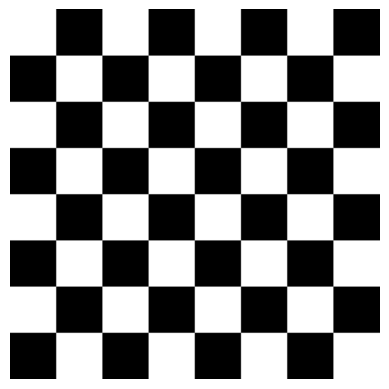

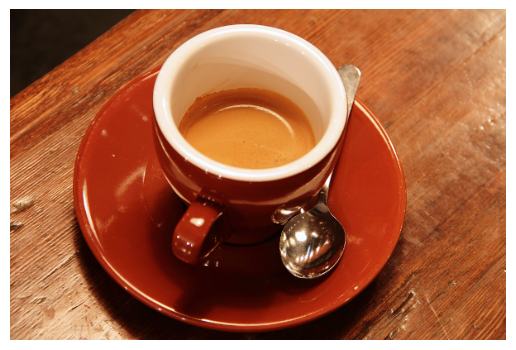

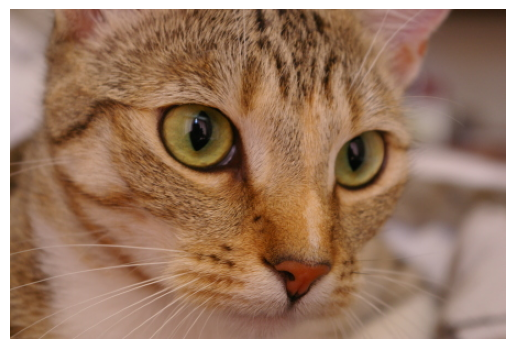

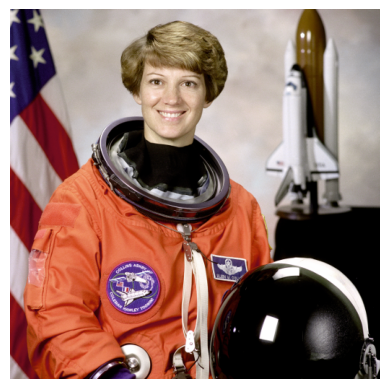

In [13]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import data

checkerboard = (data.checkerboard() > 127).astype(np.uint8) * 255
checkerboard = np.repeat(checkerboard[..., np.newaxis], 3, axis=-1)

imgs_color = [checkerboard, data.coffee(), data.cat(), data.astronaut()]
image_names = ["checkerboard", "coffee", "cat", "astronaut"]

for img in imgs_color:
    plt.imshow(img)
    plt.axis('off')
    plt.show()


Metoda działa na obrazach w skali szarości (8 bit), więc obrazy kolorowe konwertujemy do `uint8` (8-bitowa liczba całkowita bez znaku). Zestaw zawiera też szachownicę - przypadek skrajny, w którym wszystkie piksele mają wartość $0$ lub $255$.

checkerboard  shape=(200, 200), dtype=uint8, zakres=[0, 255]
coffee        shape=(400, 600), dtype=uint8, zakres=[0, 255]
cat           shape=(300, 451), dtype=uint8, zakres=[4, 193]
astronaut     shape=(512, 512), dtype=uint8, zakres=[0, 255]


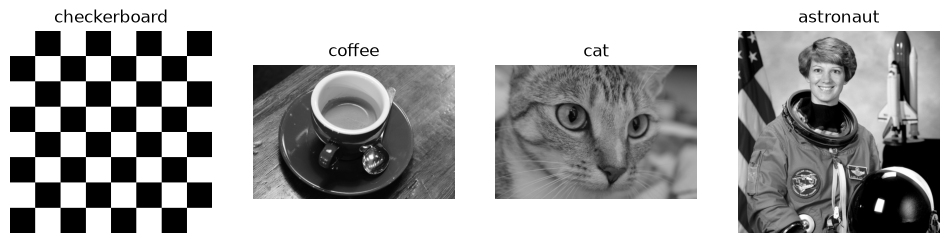

In [14]:
from skimage.color import rgb2gray

imgs_gray = [np.round(rgb2gray(img) * 255).astype(np.uint8) for img in imgs_color]

for name, img in zip(image_names, imgs_gray):
    print(f"{name:13s} shape={img.shape}, dtype={img.dtype}, zakres=[{img.min()}, {img.max()}]")


fig, axes = plt.subplots(1, len(imgs_gray), figsize=(12, 3))
for ax, name, img in zip(axes, image_names, imgs_gray):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis("off")
plt.show()

## Implementacja

### Funkcja $f$ i kolejność pikseli

`f` to funkcja binarna z artykułu. `pixel_pairs` zamienia klucz na pseudolosową permutację pikseli i dzieli ją na rozłączne pary - ta sama kolejność jest potrzebna przy osadzaniu i odczycie.

In [15]:
def f(a, b):
    """f(a, b) = LSB(floor(a / 2) + b); działa na liczbach i tablicach."""
    return ((a >> 1) + b) & 1


def pixel_pairs(n_pixels, key):
    """Pseudolosowa kolejność pikseli (klucz = ziarno) podzielona na rozłączne pary."""
    order = np.random.default_rng(key).permutation(n_pixels)
    n_pairs = n_pixels // 2
    return order[0:2 * n_pairs:2], order[1:2 * n_pairs:2]

### Osadzanie

Pętla po parach realizuje tabelę z sekcji 1. Słownik `balance` śledzi sumę zmian w obszarach o parzystych i nieparzystych wartościach oryginału, a `step` wybiera kierunek $\pm 1$, który tę sumę zbliża do zera (i nie wychodzi poza $[0, 255]$).

In [ ]:
def lsbmr_embed(cover, bits, key=0):
    """Osadza ciąg bitów (0/1) w obrazie w skali szarości metodą LSBMR."""
    bits = np.asarray(bits, dtype=np.uint8)
    if len(bits) % 2: # LSBMR koduje bity parami -przy nieparzystej liczbie bitów dopisuje na końcu jedno 0
        bits = np.append(bits, 0)
    x = cover.ravel().astype(np.int16) #spłaszcza obraz 2D do jednowymiarowej tablicy
    first, second = pixel_pairs(x.size, key)
    n_pairs = len(bits) // 2
    #asercja - jeśli próbujemy ukryć więcej bitów, niż obraz ma piksel - błąd
    assert n_pairs <= len(first), "wiadomość za długa (pojemność: 1 bit / piksel)"

    y = x.copy()
    balance = {0: 0, 1: 0} # osobno zlicza bilans zmian dla pikseli pierwotnie parzystych (0) i nieparzystych (1)

    def step(v):
        """Kierunek ±1 dla piksela o wartości v: zmniejsza |balance| jego obszaru."""
        if v == 0:
            return 1
        if v == 255:
            return -1
        return 1 if balance[v & 1] <= 0 else -1

    for k in range(n_pairs):
        i, j = first[k], second[k]
        #W każdym kroku pobierana jest jedna para pikseli (xi, xj)
        xi, xj = int(x[i]), int(x[j])
        #i para bitów wiadomości (m1, m2)
        m1, m2 = int(bits[2 * k]), int(bits[2 * k + 1])
        yi, yj = xi, xj

        #przypadek 1: pierwszy bit się nie zgadza
        if (xi & 1) != m1:
            # LSB się nie zgadza: x_i ± 1 daje dobry LSB, a wybór kierunku ustawia f = m2
            cands = [c for c in (xi - 1, xi + 1) if 0 <= c <= 255]
            ok = [c for c in cands if f(c, xj) == m2]
            if ok:
                yi = ok[0]
            else: # brzeg zakresu: dodatkowo koryguj y_j
                yi = cands[0]
                yj = xj + step(xj)
        #przypadek 2: pierwszy bit się zgadza, ale drugi nie 
        elif f(xi, xj) != m2:
            yj = xj + step(xj) # każda zmiana x_j o 1 odwraca f
        #przypadek 3: oba bity się zgadzają - brak zmian

        #zapis i przywrócenie kształtu obrazu
        y[i], y[j] = yi, yj
        balance[xi & 1] += yi - xi
        balance[xj & 1] += yj - xj

    return y.reshape(cover.shape).astype(np.uint8)

### Odczyt i metody odniesienia

Odczyt nie wymaga oryginału: z każdej pary bierzemy $\mathrm{LSB}(y_i)$ oraz $f(y_i, y_{i+1})$. Dodajemy też **LSB matching** i **LSB replacement** (osadzanie 1 bit/piksel w tych samych pikselach), żeby porównać liczbę zmian i asymetrię.

In [ ]:
def lsbmr_extract(stego, n_bits, key=0):
    """odczytuje wiadomość ukrytą metodą LSBMR: """
    y = stego.ravel().astype(np.int16)
    first, second = pixel_pairs(y.size, key) #odtwarza dokładnie tę samą kolejność par pikseli, której użył nadawca (dzięki wspólnemu key)
    n_pairs = (n_bits + 1) // 2 #oblicza liczbę par potrzebnych do odczytania n_bits bitów
    a, b = y[first[:n_pairs]], y[second[:n_pairs]] #pobiera tablice pierwszych (a) i drugich (b) pikseli z tych par
    bits = np.empty(2 * n_pairs, dtype=np.uint8)
    #wpisuje odczytane bity naprzemiennie do tablicy wynikowej
    # na pozycje parzyste trafia a & 1 (pierwszy bit z każdej pary)
    # na pozycje nieparzyste trafia f(a, b) (drugi bit z każdej pary)
    bits[0::2], bits[1::2] = a & 1, f(a, b) 
    return bits[:n_bits] #ucina ewentualny nadmiarowy bit dopełnienia


def lsb_matching_embed(cover, bits, key=0, seed=1):
    """LSB matching: losowo dodaje lub odejmuje 1 od wartości piksela (metoda odniesienia)."""
    bits = np.asarray(bits, dtype=np.uint8)
    x = cover.ravel().astype(np.int16)
    idx = np.random.default_rng(key).permutation(x.size)[:len(bits)]
    step = np.random.default_rng(seed).choice([-1, 1], size=len(bits))
    step[x[idx] == 0], step[x[idx] == 255] = 1, -1   # nie wychodzi poza [0, 255]
    y = x.copy()
    y[idx] += step * ((x[idx] & 1) != bits)
    return y.reshape(cover.shape).astype(np.uint8)


def lsb_replacement_embed(cover, bits, key=0):
    """LSB replacement: nadpisuje ostatni bit wartością bitu wiadomości."""
    bits = np.asarray(bits, dtype=np.uint8)
    x = cover.ravel().astype(np.int16)
    idx = np.random.default_rng(key).permutation(x.size)[:len(bits)]
    y = x.copy()
    #tworzy maskę, która ma same jedynki i zero na ostatniej pozycji, 
    # zeruje ostatni bit (LSB) piksela, nie ruszając pozostałych 7 bitów
    #wstawia bit wiadomości (0 lub 1) dokładnie na to wyzerowane ostatnie miejsce
    y[idx] = (x[idx] & ~1) | bits 
    return y.reshape(cover.shape).astype(np.uint8)

## Użycie

W każdym z czterech obrazów osadzamy wiadomość o maksymalnej długości (1 bit/piksel): krótki tekst uzupełniony losowymi bitami (jak w artykule, gdzie ładunek przypomina zaszyfrowane dane). LSBMR odczytuje całość i sprawdzamy, czy tekst został odzyskany (potrzebny jest ten sam `key` i długość wiadomości w bitach). Rysunek pokazuje oryginał, obraz stego i mapę różnic (biały = zmieniony piksel), a tabela porównuje trzy metody:
- `mods/pixel` – ułamek zmienionych pikseli
- `|bias|` – moduł średniej zmiany piksela (stego − oryginał) osobno dla pikseli o parzystej i nieparzystej wartości oryginału 

checkerboard  odczytany tekst: 'LSB matching revisited'
coffee        odczytany tekst: 'LSB matching revisited'
cat           odczytany tekst: 'LSB matching revisited'
astronaut     odczytany tekst: 'LSB matching revisited'


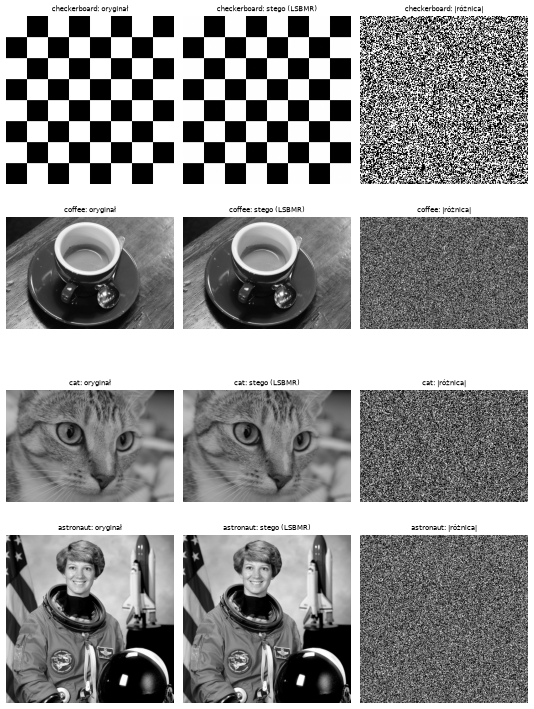

,image,method,mods/pixel,|bias| even,|bias| odd
0,checkerboard,LSB replacement,0.503,0.497,0.510
1,checkerboard,LSB matching,0.503,0.497,0.510
2,checkerboard,LSBMR,0.498,0.494,0.503
3,coffee,LSB replacement,0.499,0.500,0.499
4,coffee,LSB matching,0.499,0.001,0.001
5,coffee,LSBMR,0.376,0.000,0.000
6,cat,LSB replacement,0.502,0.501,0.502
7,cat,LSB matching,0.502,0.004,0.001
8,cat,LSBMR,0.375,0.000,0.000
9,astronaut,LSB replacement,0.502,0.502,0.502


In [ ]:
import pandas as pd

text = "LSB matching revisited"
text_bits = np.unpackbits(np.frombuffer(text.encode(), dtype=np.uint8))

methods = {"LSB replacement": lsb_replacement_embed,
           "LSB matching": lsb_matching_embed,
           "LSBMR": lsbmr_embed}
rng = np.random.default_rng(42)
rows = []
fig, axes = plt.subplots(len(imgs_gray), 3, figsize=(9, 3 * len(imgs_gray)), dpi=60)

for name, gray, ax_row in zip(image_names, imgs_gray, axes):
    # wiadomość: tekst + losowe bity do pełnej pojemności (1 bit / piksel)
    padding = rng.integers(0, 2, gray.size - text_bits.size, dtype=np.uint8)
    bits = np.concatenate([text_bits, padding])

    for method, embed in methods.items():
        stego = embed(gray, bits, key=123)
        #mapa różnic między obrazem stego a oryginałem
        diff = stego.astype(int) - gray.astype(int)
        #maska logiczna wskazująca piksele pierwotnie parzyste
        even = gray % 2 == 0
        rows.append({"image": name, "method": method,
                     "mods/pixel": np.mean(diff != 0), #odsetek zmodyfikowanych pikseli
                     "|bias| even": abs(diff[even].mean()), #wartość bezwzględna ze średniej zmiany osobno dla pikseli parzystych i nieparzystych
                     "|bias| odd": abs(diff[~even].mean())})

        if method == "LSBMR":
            extracted = lsbmr_extract(stego, bits.size, key=123)
            assert np.array_equal(extracted, bits)
            recovered = np.packbits(extracted[:text_bits.size]).tobytes().decode()
            print(f"{name:13s} odczytany tekst: {recovered!r}")
            panels = [(gray, 255, "oryginał"), (stego, 255, "stego (LSBMR)"), (np.abs(diff), 1, "|różnica|")]
            for ax, (im, vmax, title) in zip(ax_row, panels):
                ax.imshow(im, cmap="gray", vmin=0, vmax=vmax)
                ax.set_title(f"{name}: {title}", fontsize=8)
                ax.axis("off")

plt.tight_layout()
plt.show()
pd.DataFrame(rows).round(3)

W ramach eksperymentu porównano trzy metody steganografii przestrzennej - **LSB replacement**, **LSB matching** oraz **LSB Matching Revisited (LSBMR)**. Ocenie poddano odsetek zmodyfikowanych pikseli (`mods/pixel`) oraz asymetrię zmian osobno dla pikseli parzystych (`|bias| even`) i nieparzystych (`|bias| odd`).

### Analiza wyników 

* **Obrazy naturalne (`coffee`, `cat`):** Wyniki potwierdzają teorię. *LSB replacement* zmienia ~50% pikseli i tworzy silną asymetrię (`|bias| ≈ 0.500`). *LSB matching* usuwa asymetrię (`|bias| ≈ 0.001–0.004`), lecz nadal modyfikuje ~50% pikseli. **LSBMR** obniża liczbę zmian do teoretycznych **37,5%** (`0.375–0.376`) przy zerowej asymetrii (`0.000`).
* **Przypadek skrajny (`checkerboard`):** Wszystkie metody uzyskały słabe wyniki (`mods/pixel ≈ 0.500`, `|bias| ≈ 0.500`). Szachownica składa się wyłącznie z wartości brzegowych `0` i `255` - brak możliwości wyboru kierunku zmiany (`0 → +1`, `255 → -1`) degraduje *LSB matching* i *LSBMR* do zachowania zwykłego *LSB replacement*.
* **Obszary nasycone (`astronaut`):** Duża liczba czarnych pikseli (`0`) na kasku i w tle podnosi asymetrię parzystych w *LSB matching* (`|bias| even = 0.100`) oraz lekko zwiększa liczbę zmian w *LSBMR* (`0.389`). W *LSBMR* mechanizm równoważenia (`balance`) kompensuje jednak ten efekt, utrzymując asymetrię na poziomie `0.000`.
* **Ocena wizualna:** Obrazy wynikowe (stego) są nieodróżnialne od oryginałów. Mapy różnic (`|różnica|`) mają postać równomiernego szumu bez śladów struktury zdjęć (poprawne rozproszenie bitów), a gęstość zmian na szachownicy jest wyraźnie wyższa niż na zdjęciach naturalnych.

**Wniosek:** Dla naturalnych fotografii **LSBMR** jest najbardziej efektywną metodą - gwarantuje bezbłędny odczyt przy najmniejszej liczbie modyfikacji i zerowej asymetrii. Jego skuteczność spada jednak na obrazach z dużym udziałem pikseli brzegowych (`0` i `255`).
